In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
datos = np.genfromtxt('datos-01.txt')

x =datos[:,0]
y =datos[:,1]

Vamos a usar de base $y_n(x)\cos(xn\pi) = 5, n=0...,4 

In [3]:
n = np.arange(0,5,1)
print(n)

[0 1 2 3 4]


[[ 1.          0.80901699  0.30901699 -0.30901699 -0.80901699]
 [ 1.          0.30901699 -0.80901699 -0.80901699  0.30901699]
 [ 1.         -0.30901699 -0.80901699  0.80901699  0.30901699]
 [ 1.         -0.80901699  0.30901699  0.30901699 -0.80901699]
 [ 1.         -1.          1.         -1.          1.        ]]
[1. 4. 3. 4. 5.]


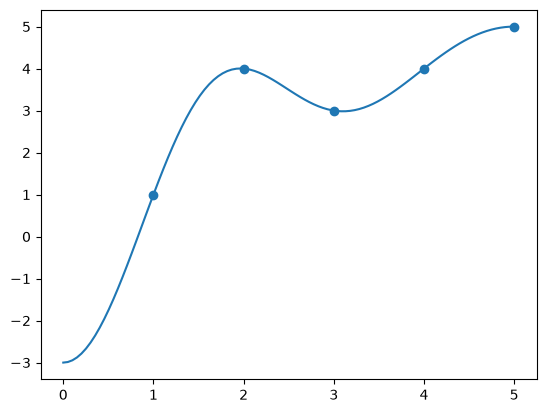

In [4]:
N = len(x)-1
def phi (x,n):
    L= 5
    return np.cos(n*np.pi*x/L)

M = np.zeros((N+1,N+1))
Y = np.zeros(N+1)
for i in range (N+1):
    for j in range(N+1):
        M[i,j] = phi(x[i],j)
    Y[i] = y[i]
print(M)
print(Y) 
a0,a1,a2,a3,a4 = np.linalg.solve(M,Y)
A = np.linalg.solve(M,Y)

def f(x):
    return a0+a1*phi(1,x)+a2*phi(2,x)+a3*phi(3,x)+a4*phi(4,x)
plt.plot(np.linspace(0,5,100),f(np.linspace(0,5,100)))
plt.scatter(x,y)

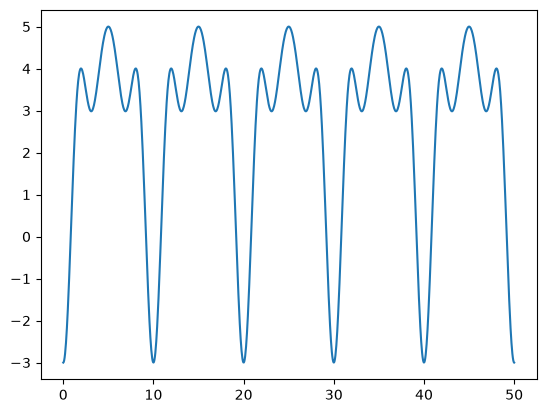

In [5]:
plt.plot(np.linspace(0,50,1000),f(np.linspace(0,50,1000)))

Ya que estamos interpolando con funciones periodicas (cos) tenemos que se repite 

Coeficientes: [ 2.6       -2.4472136 -1.2472136 -1.5527864 -0.3527864]
Valores interpolados: [1. 4. 3. 4. 5.]
Coincide con los datos: True


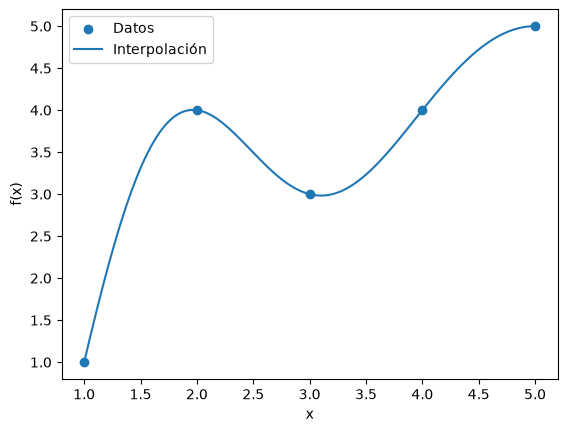

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Leer los datos
datos = np.genfromtxt("datos-01.txt")
x = datos[:, 0]
y = datos[:, 1]

N = len(x) - 1
L = 5

# 2. Definir las funciones base
def phi(x, j):
    return np.cos(j * np.pi * x / L)

# 3. Construir la matriz
M = np.zeros((N + 1, N + 1))

for i in range(N + 1):
    for j in range(N + 1):
        M[i, j] = phi(x[i], j)

# 4. Resolver el sistema M @ A = y
A = np.linalg.solve(M, y)

# 5. Construir la función interpoladora
def f(z):
    suma = 0.0
    for j in range(N + 1):
        suma += A[j] * phi(z, j)
    return suma

# 6. Verificar y graficar
print("Coeficientes:", A)
print("Valores interpolados:", f(x))
print("Coincide con los datos:", np.allclose(f(x), y))

z = np.linspace(x.min(), x.max(), 300)

plt.scatter(x, y, label="Datos")
plt.plot(z, f(z), label="Interpolación")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.show()


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Datos originales
datos = np.genfromtxt("datos-01.txt")
x = datos[:, 0]
y = datos[:, 1]

n = len(x)
h = np.diff(x)

# Matriz y vector del sistema
M = np.zeros((n, n))
B = np.zeros(n)

# Condiciones de borde naturales
M[0, 0] = 1
M[-1, -1] = 1

# Ecuaciones en los puntos interiores
for i in range(1, n - 1):
    M[i, i-1] = h[i-1]
    M[i, i] = 2 * (h[i-1] + h[i])
    M[i, i+1] = h[i]

    B[i] = 6 * (
        (y[i+1] - y[i]) / h[i]
        - (y[i] - y[i-1]) / h[i-1]
    )

# Resolver las segundas derivadas
m = np.linalg.solve(M, B)

# Coeficientes de cada polinomio cúbico
a = y[:-1]
b = (y[1:] - y[:-1])/h - h*(2*m[:-1] + m[1:])/6
c = m[:-1]/2
d = (m[1:] - m[:-1])/(6*h)

# Evaluación del spline
def spline(z):
    z = np.asarray(z)
    i = np.searchsorted(x, z, side="right") - 1
    i = np.clip(i, 0, n-2)

    t = z - x[i]
    return a[i] + b[i]*t + c[i]*t**2 + d[i]*t**3

# Gráfica
z = np.linspace(x[0], x[-1], 300)

plt.scatter(x, y, label="Datos")
plt.plot(z, spline(z), label="Spline cúbico")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()
